In [1]:
%pip install ICIW_Plots
%pip install cma
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime
import pandas as pd
import glob
from scipy.constants import R
from scipy.integrate import solve_ivp
from scipy.signal import correlate, correlation_lags
from pathlib import Path
import sys
import inspect


from AZA_THB_solver import *
from AZA_THB_tools import *
from AZA_THB_reactor_input import *
from AZA_THB_reactor_output_II import *
from AZA_THB_optimizer_II import Optimizer

if 'ICIWstyle' in plt.style.available:
    plt.style.use('ICIWstyle')

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip

[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.
['Ar', 'He', 'H2', 'CO', 'CO2', 'CH4', 'H2O', 'CH6', 'C3H8', 'Ne', 'C4', 'C5', 'C6', 'C2en', 'C3en', 'star', 'CO2_s', 'CO_s', 'COin_s', 'CH_s', 'CH2_s', 'O_s', 'H_s', 'HCO_s', 'OH_s', 'H2O_s', 'x', 'H_x', 'HCOO_x', 'OH_x', 'H2O_x']
[[ 0  0 -1  0  0  0  0  0  0  0  0  0  0  0  0 -2  0  0  0  0  0  0  2  0
   0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  1  0 -1  0  0  0  0 -1  1
   0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  1  0  0  0 -1
   0  0  0 -1  0  1  0]
 [ 0  0  0  0  0  1  0  0  0  0  0  0  0  0  0  4  0  0  0 -1  0  0 -3  0
   0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  1  0  0  0  0  0  0 -1  0
   0  0 -1  1  0  0  0]
 [ 0  0  0  0 -1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
   0  0  0 -1  1  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  

'-AZA_solver- imported at'

'2026-09-11 10:21:58'

'-AZA_fancy_tools- imported at'

... (3 outputs left out)

'-AZA_THB_reactor_output- imported at'

'2026-09-11 10:21:58'

'-AZA_THB_optimizer- imported at'

'2026-09-11 10:21:58'

In [2]:
FILES = {
    '2 bar': r'Data files\Run_2026-08-05_114101_2bar_150grad_250nml-min_caphsa_reope_ohneMatrix.npy',
    '1 bar':      r'Data files\Run_2026-08-14_115231_1bar_150grad_250nml-min_caphsa_reope_ohneMatrix.npy',
    '2 bar mit Matrix':   r'Data files\Run_2026-07-30_090759_2bar_150grad_250nml-min_caphsa_reope.npy',
}
ALIGN   = 'onset'      # gemeinsamer Startpunkt bei F = 1 %
SAVE_AS = 'gesamt_vwzv.pdf'

Gesamt-VWZV  E1 (x) E2 (x) E3 (x) E4       Ausrichtung: onset
Lauf                          tau    sigma      t50    t10-90   Totzeit  sigma/tau     Shift
2 bar                      45.28s    4.57s   43.83s    10.13s    39.88s     0.1010   -39.88s
1 bar                      27.39s    4.13s   26.16s     9.14s    22.28s     0.1508   -22.28s
2 bar mit Matrix           45.14s    4.32s   43.74s     9.22s    40.27s     0.0956   -40.27s

Momente der Einzelstufen  (tau / sigma in s):
Lauf                                  E1              E2              E3              E4
2 bar                        14.60/ 1.40    16.53/ 3.48    11.82/ 0.73     2.26/ 2.25
1 bar                         7.94/ 1.69     6.75/ 2.71    10.44/ 1.28     2.24/ 2.19
2 bar mit Matrix             16.64/ 1.60    13.29/ 3.28    12.93/ 0.43     2.25/ 2.15

sigma/tau ist die dimensionslose Streuung: klein bedeutet nahe an
Pfropfenstroemung. Sie ist unabhaengig von der Totzeit und deshalb die
fairste Vergleichsgroesse zwischen

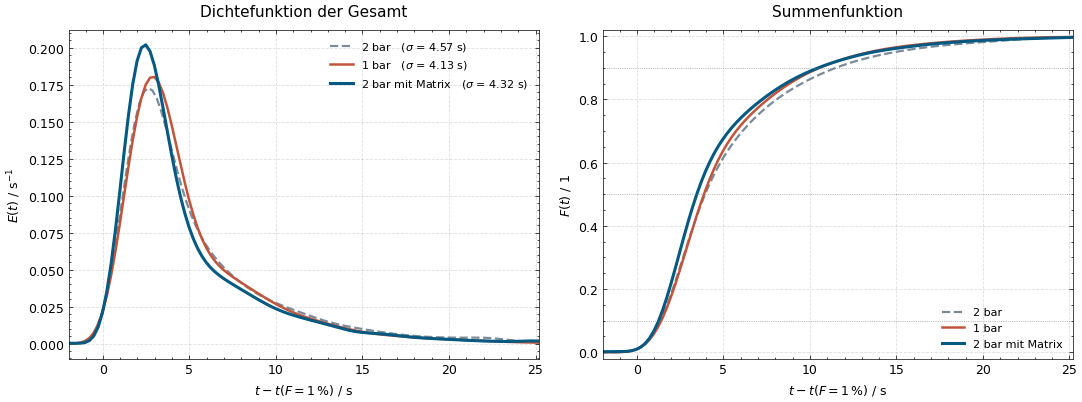

In [3]:
"""
===============================================================================
 Vergleich der Gesamt-Verweilzeitverteilung E1 (x) E2 (x) E3 (x) E4
 aus mehreren nRTD-Trainingslaeufen
===============================================================================

WAS DAS SKRIPT MACHT
--------------------
Fuer jeden Trainingslauf werden die vier Einzelkerne zu einer Gesamt-VWZV
verkettet und uebereinandergelegt:

    E_ges(t) = E1 (x) E2 (x) E3 (x) E4

Zwei Panels:
    links   Dichtefunktion E(t)   - zeigt Form, Breite und Schiefe
    rechts  Summenfunktion F(t)   - Totzeit und t50 direkt ablesbar

WARUM DIE KURVEN AUSGERICHTET WERDEN
------------------------------------
Die Laeufe haben unterschiedliche Gesamtverweilzeiten (Totvolumen, Bypass,
Kapillarlaenge). Ohne Ausrichtung liegen sie nebeneinander statt uebereinander,
und man vergleicht Verzoegerungen statt Formen. Interessant ist hier aber die
DISPERSION - also wie stark ein Sprung verschmiert wird. Deshalb werden die
Kurven auf einen gemeinsamen Startpunkt geschoben:

    ALIGN = 'onset'   gemeinsamer Startpunkt bei F(t) = ONSET_LEVEL (Default 1 %)
                      Das ist die Totzeit: der erste Zeitpunkt, an dem ueberhaupt
                      etwas ankommt. Fuer den Formvergleich das natuerlichste
                      Kriterium und die uebliche Wahl im Bericht.
    ALIGN = 't50'     Ausrichtung an der Medianverweilzeit
    ALIGN = 'tau'     Ausrichtung am Erwartungswert (mittlere Verweilzeit)
    ALIGN = 'none'    Rohlage auf absoluter Zeitachse - fuer den Vergleich der
                      Verzoegerungen statt der Formen

Die Verschiebung wird in der Konsolenausgabe mitgeschrieben, damit im Bericht
nachvollziehbar bleibt, um wie viel jede Kurve geschoben wurde.

WICHTIG
-------
Die Kerne werden vor dem Verketten einzeln auf Integral 1 normiert. Die
Rohwerte aus dem Training liegen typisch 0,2 bis 0,6 % daneben, und ueber vier
Stufen multiplizieren sich diese Fehler auf.
===============================================================================
"""
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------- Einstellungen -------------------------------
# Beschriftung -> Dateipfad. Die Reihenfolge bestimmt die Reihenfolge der Legende.
# FILES = {
#     'Referenz (2025-06-30)': r'Data files\Run_2025-06-30_144137.npy',
#     'Bypass-Kapillare':      r'Data files\Run_2026-07-29_123209_2bar_150grad_250nml-min_reope.npy',
#     'caphsa, ohne Matrix':   r'Data files\Run_2026-08-05_114101_2bar_150grad_250nml-min_caphsa_reope_ohneMatrix.npy',
# }

COLORS = ['#7A8B99', '#C1553B', '#065A82']    # grau, terrakotta, blau
STYLES = ['--', '-', '-']
WIDTHS = [1.6, 1.8, 2.2]

ALIGN       = 'onset'   # 'onset' | 't50' | 'tau' | 'none'
ONSET_LEVEL = 0.01      # F(t) = 1 % gilt als Startpunkt
T_MAX       = None      # Achsenende in s; None = automatisch
NORMALIZE_E = True      # Kerne einzeln auf Integral 1 normieren
SAVE_AS     = None      # z.B. 'gesamt_vwzv.pdf' - Vektorformat fuer den Bericht
# -----------------------------------------------------------------------------


def _to_dict(obj):
    """np.load liefert je nach Speicherweise ein 0-d-Array oder direkt ein dict."""
    return obj.item() if isinstance(obj, np.ndarray) and obj.ndim == 0 else obj


def load_total_rtd(path, normalize=NORMALIZE_E, onset_level=ONSET_LEVEL):
    """Laedt einen Trainingslauf und verkettet E1..E4 zur Gesamt-VWZV.

    Erst die Kerne miteinander falten, dann erst ein Signal - das ist wegen der
    Assoziativitaet der Faltung aequivalent, aber numerisch sauberer, weil nur
    ein Randeffekt entsteht.

    Der Faktor dt kommt daher, dass np.convolve eine Summe bildet, die Faltung
    aber ein Integral ist: Integral f(t') g(t-t') dt'  ~  Summe * dt.

    Returns:
        dict mit t, E (Dichte), F (Summenfunktion), den Kennzahlen tau, sigma,
        t50, t10, t90, Totzeit sowie den Momenten der vier Einzelstufen
    """
    d = _to_dict(np.load(path, allow_pickle=True))
    ts = [np.asarray(t, float) for t in d['ts']]
    Es = [np.asarray(E, float) for E in d['Es']]

    # --- Zeitraster pruefen: alle Kerne muessen dasselbe dt haben ---
    dts = []
    for i, (t, E) in enumerate(zip(ts, Es)):
        step = np.diff(t)
        if not np.allclose(step, step[0], rtol=1e-9, atol=1e-12):
            raise ValueError(f'{path}: Kern {i} hat kein gleichmaessiges Zeitraster.')
        dts.append(step[0])
    if not np.allclose(dts, dts[0], rtol=1e-9, atol=1e-12):
        raise ValueError(f'{path}: Kerne haben verschiedene dt: {dts}')
    dt = float(dts[0])

    # --- Momente der Einzelstufen, immer aus den normierten Kernen ---
    single = []
    for t, E in zip(ts, Es):
        En = E / np.trapezoid(E, t)
        tau_i = float(np.trapezoid(t * En, t))
        sig_i = float(np.sqrt(np.trapezoid((t - tau_i) ** 2 * En, t)))
        single.append((tau_i, sig_i))

    # --- Verkettung der vier Stufen ---
    E_tot = Es[0] / np.trapezoid(Es[0], ts[0]) if normalize else Es[0]
    for i in range(1, len(Es)):
        E_i = Es[i] / np.trapezoid(Es[i], ts[i]) if normalize else Es[i]
        E_tot = np.convolve(E_tot, E_i) * dt

    t_tot = np.arange(E_tot.size) * dt
    E_tot = E_tot / np.trapezoid(E_tot, t_tot)      # Gesamtkern auf Integral 1

    # --- Summenfunktion (Trapezintegration der Dichte) ---
    F = np.concatenate(([0.0], np.cumsum(0.5 * (E_tot[1:] + E_tot[:-1]) * dt)))
    F = F / F[-1]

    # --- Kennzahlen ---
    tau = float(np.trapezoid(t_tot * E_tot, t_tot))
    sigma = float(np.sqrt(np.trapezoid((t_tot - tau) ** 2 * E_tot, t_tot)))

    return {'t': t_tot, 'E': E_tot, 'F': F, 'dt': dt,
            'tau': tau, 'sigma': sigma,
            't50': float(np.interp(0.50, F, t_tot)),
            't10': float(np.interp(0.10, F, t_tot)),
            't90': float(np.interp(0.90, F, t_tot)),
            't_onset': float(np.interp(onset_level, F, t_tot)),
            'single': single}


def shift_of(r, mode=ALIGN):
    """Zeitverschiebung, die den gewaehlten Bezugspunkt auf t = 0 legt."""
    return {'onset': r['t_onset'], 't50': r['t50'], 'tau': r['tau']}.get(mode, 0.0)


# ================================ Berechnung =================================
res = {name: load_total_rtd(path) for name, path in FILES.items()}

label_x = {'onset': f'$t - t(F = {ONSET_LEVEL * 100:.0f}\\,\\%)$ / s',
           't50':   '$t - t_{50}$ / s',
           'tau':   r'$t - \tau$ / s',
           'none':  '$t$ / s'}[ALIGN]

print('=' * 92)
print(f'Gesamt-VWZV  E1 (x) E2 (x) E3 (x) E4       Ausrichtung: {ALIGN}')
print('=' * 92)
print(f'{"Lauf":24s} {"tau":>8s} {"sigma":>8s} {"t50":>8s} {"t10-90":>9s} '
      f'{"Totzeit":>9s} {"sigma/tau":>10s} {"Shift":>9s}')
for name, r in res.items():
    print(f'{name:24s} {r["tau"]:7.2f}s {r["sigma"]:7.2f}s {r["t50"]:7.2f}s '
          f'{r["t90"] - r["t10"]:8.2f}s {r["t_onset"]:8.2f}s '
          f'{r["sigma"] / r["tau"]:10.4f} {-shift_of(r):8.2f}s')

print()
print('Momente der Einzelstufen  (tau / sigma in s):')
print(f'{"Lauf":24s} {"E1":>15s} {"E2":>15s} {"E3":>15s} {"E4":>15s}')
for name, r in res.items():
    cells = ''.join(f'{tau:9.2f}/{sig:5.2f}' for tau, sig in r['single'])
    print(f'{name:24s} {cells}')

print()
print('sigma/tau ist die dimensionslose Streuung: klein bedeutet nahe an')
print('Pfropfenstroemung. Sie ist unabhaengig von der Totzeit und deshalb die')
print('fairste Vergleichsgroesse zwischen Laeufen mit verschiedenem Totvolumen.')

# ================================== Plot =====================================
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

for i, (name, r) in enumerate(res.items()):
    t = r['t'] - shift_of(r)
    col = COLORS[i % len(COLORS)]
    ls = STYLES[i % len(STYLES)]
    lw = WIDTHS[i % len(WIDTHS)]

    axes[0].plot(t, r['E'], color=col, linestyle=ls, lw=lw,
                 label=f'{name}   ($\\sigma$ = {r["sigma"]:.2f} s)')
    axes[1].plot(t, r['F'], color=col, linestyle=ls, lw=lw, label=name)

# --- linkes Panel: Dichtefunktion ---
axes[0].set_xlabel(label_x)
axes[0].set_ylabel(r'$E(t)$ / s$^{-1}$')
axes[0].set_title('Dichtefunktion der Gesamt', fontsize=11)
axes[0].legend(fontsize=8, frameon=False)
axes[0].grid(alpha=0.25, lw=0.6)

# --- rechtes Panel: Summenfunktion mit Ablesehilfen bei 10, 50 und 90 % ---
for lvl in (0.1, 0.5, 0.9):
    axes[1].axhline(lvl, color='gray', lw=0.5, ls=':')
axes[1].set_xlabel(label_x)
axes[1].set_ylabel(r'$F(t)$ / 1')
axes[1].set_ylim(-0.02, 1.02)
axes[1].set_title('Summenfunktion', fontsize=11)
axes[1].legend(fontsize=8, frameon=False, loc='lower right')
axes[1].grid(alpha=0.25, lw=0.6)

# --- gemeinsame Achsenbegrenzung ---
# rechts: bis alle Kurven bei F = 99,5 % sind
# links: nur ein kleiner Rand vor dem Bezugspunkt. Ohne diese Begrenzung reicht
# die Achse bis -tau zurueck (bei 'onset' rund -40 s) und der interessante
# Bereich wird an den rechten Rand gedrueckt.
t_end = (max(np.interp(0.995, r['F'], r['t']) - shift_of(r) for r in res.values())
         if T_MAX is None else T_MAX)
t_raw = min((r['t'] - shift_of(r))[0] for r in res.values())
t_start = 0.0 if ALIGN == 'none' else max(t_raw, -0.08 * t_end)
for ax in axes:
    ax.set_xlim(t_start, t_end * 1.03)

plt.tight_layout()
if SAVE_AS:
    plt.savefig(SAVE_AS, dpi=300, bbox_inches='tight')
    print(f'\nGespeichert: {SAVE_AS}')
plt.show()

Einzelkerne: Momente und Varianzanteile
Lauf                                 E1             E2             E3             E4
2 bar                      14.60/ 1.40   16.53/ 3.48   11.82/ 0.73    2.26/ 2.25      (tau / sigma in s)
1 bar                       7.94/ 1.69    6.75/ 2.71   10.44/ 1.28    2.24/ 2.19      (tau / sigma in s)
2 bar mit Matrix           16.64/ 1.60   13.29/ 3.28   12.93/ 0.43    2.25/ 2.15      (tau / sigma in s)

Lauf                                 E1             E2             E3             E4    sigma_ges
2 bar                             10.0%          61.6%           2.7%          25.7%        4.43s
1 bar                             17.3%          44.1%           9.8%          28.9%        4.08s
2 bar mit Matrix                  14.2%          59.4%           1.0%          25.4%        4.26s

Varianzen addieren sich entlang der Kette. Verschiebt sich der Anteil
zwischen zwei Laeufen von einer Stufe auf eine andere, waehrend sigma_ges
gleich bleibt, wurde d

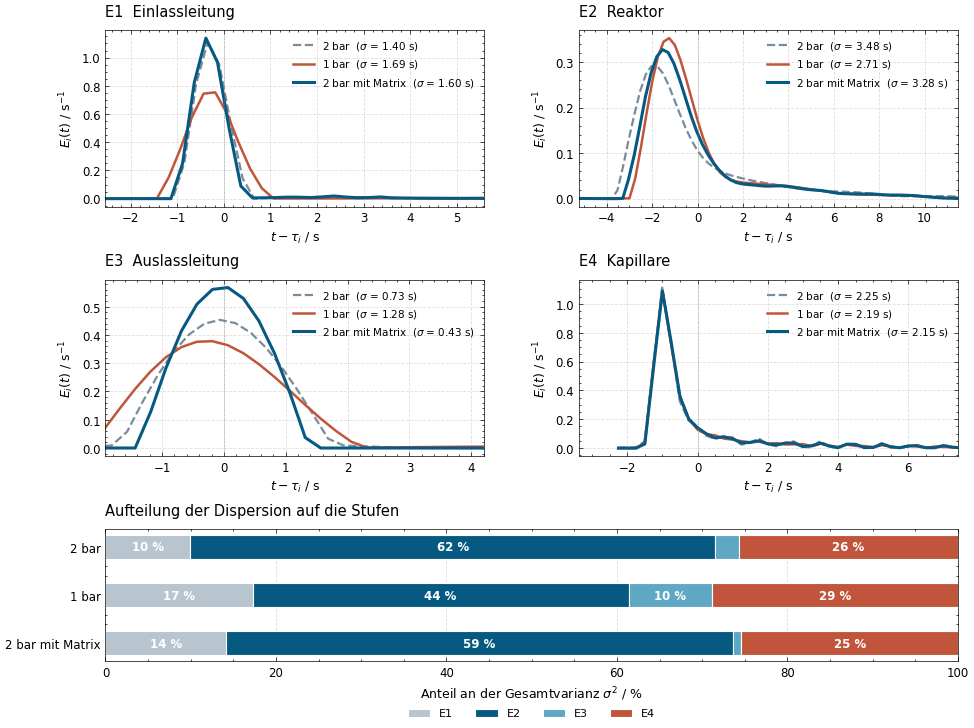

In [4]:
"""
===============================================================================
 Vergleich der EINZELKERNE E1 bis E4 aus mehreren nRTD-Trainingslaeufen
 (Ergaenzung zu plot_gesamt_vwzv.py)
===============================================================================

WARUM DIESE ZWEITE ABBILDUNG
----------------------------
Die Gesamt-VWZV E1 (x) E2 (x) E3 (x) E4 sieht in allen Laeufen fast gleich aus
(tau auf 0,2 s identisch, sigma 4,15 gegen 4,57 s). Das ist kein Zufall: alle
Laeufe wurden gegen dieselbe Gesamtsystemmessung gefittet, die Gesamtuebertragung
MUSS also stimmen.

Der Unterschied steckt in der Aufteilung auf die Stufen - und die ist fuer das
Reaktormodell entscheidend, weil die Kinetik zwischen E1 und E2 gesetzt wird.
Diese Abbildung macht genau das sichtbar.

    plot_gesamt_vwzv.py   -> Beleg, dass die Gesamtuebertragung stabil ist
    dieses Skript         -> zeigt, wo sich die Laeufe tatsaechlich unterscheiden

AUFBAU
------
2x2-Raster, ein Panel je Stufe. In jedem Panel liegen alle Laeufe uebereinander.
Optional werden die Kerne an ihrem Erwartungswert ausgerichtet (ALIGN_SINGLE),
damit man die Breiten direkt vergleichen kann, ohne dass unterschiedliche
Verzugszeiten die Kurven auseinanderziehen.

Zusaetzlich unten: ein gestapeltes Balkendiagramm der Varianzanteile. Varianzen
addieren sich entlang der Kette, der Anteil jeder Stufe an sigma_gesamt^2 ist
also eine saubere Aufteilung, die sich zu 100 % summiert.

LESEHILFE
---------
    tau     Verweilzeit der Stufe  -> wo die Kurve liegt
    sigma   Dispersion der Stufe   -> wie breit sie ist
Verschiebt sich sigma zwischen zwei Laeufen von einer Stufe auf eine andere,
waehrend die Summe gleich bleibt, ist die Dispersion umverteilt worden - nicht
neu entstanden.
===============================================================================
"""
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------- Einstellungen -------------------------------
# FILES = {
#     'Referenz (2025-06-30)': r'Data files\Run_2025-06-30_144137.npy',
#     'Bypass-Kapillare':      r'Data files\Run_2026-07-29_123209_2bar_150grad_250nml-min_reope.npy',
#     'caphsa, ohne Matrix':   r'Data files\Run_2026-08-05_114101_2bar_150grad_250nml-min_caphsa_reope_ohneMatrix.npy',
# }

KERNEL_NAME = ['E1  Einlassleitung', 'E2  Reaktor',
               'E3  Auslassleitung', 'E4  Kapillare']

COLORS = ['#7A8B99', '#C1553B', '#065A82']    # grau, terrakotta, blau
STYLES = ['--', '-', '-']
WIDTHS = [1.6, 1.8, 2.2]

ALIGN_SINGLE = 'tau'    # 'tau' = auf den Erwartungswert schieben, 'none' = Rohlage
X_PAD        = 1.5      # Fensterbreite als Vielfaches von sigma (nur bei 'tau')
SHOW_BARS    = True     # gestapeltes Balkendiagramm der Varianzanteile anhaengen
SAVE_AS      = None     # z.B. 'einzelkerne.pdf' - Vektorformat fuer den Bericht
# -----------------------------------------------------------------------------


def _to_dict(obj):
    """np.load liefert je nach Speicherweise ein 0-d-Array oder direkt ein dict."""
    return obj.item() if isinstance(obj, np.ndarray) and obj.ndim == 0 else obj


def load_kernels(path):
    """Laedt die vier Einzelkerne eines Trainingslaufs, normiert auf Integral 1.

    Die Normierung ist nicht kosmetisch: die Rohwerte aus dem Training liegen
    typisch 0,2 bis 0,6 % neben eins. Ohne sie waeren schon die Flaechen unter
    den Kurven verschieden und ein Formvergleich waere sinnlos.

    Returns:
        Liste von dicts mit t, E, tau, sigma - eine je Stufe
    """
    d = _to_dict(np.load(path, allow_pickle=True))
    out = []

    for t, E in zip(d['ts'], d['Es']):
        t = np.asarray(t, float)
        E = np.asarray(E, float)

        step = np.diff(t)
        if not np.allclose(step, step[0], rtol=1e-9, atol=1e-12):
            raise ValueError(f'{path}: Kern mit ungleichmaessigem Zeitraster.')

        En = E / np.trapezoid(E, t)
        tau = float(np.trapezoid(t * En, t))
        sigma = float(np.sqrt(np.trapezoid((t - tau) ** 2 * En, t)))
        out.append({'t': t, 'E': En, 'tau': tau, 'sigma': sigma})

    return out


# ================================ Berechnung =================================
runs = {name: load_kernels(path) for name, path in FILES.items()}
n_k = min(len(v) for v in runs.values())

print('=' * 88)
print('Einzelkerne: Momente und Varianzanteile')
print('=' * 88)
print(f'{"Lauf":24s} ' + ' '.join(f'{KERNEL_NAME[i].split()[0]:>14s}' for i in range(n_k)))

var_share = {}
for name, ks in runs.items():
    var_tot = sum(k['sigma'] ** 2 for k in ks[:n_k])
    var_share[name] = [k['sigma'] ** 2 / var_tot * 100 for k in ks[:n_k]]
    cells = ' '.join(f'{k["tau"]:7.2f}/{k["sigma"]:5.2f}' for k in ks[:n_k])
    print(f'{name:24s} {cells}      (tau / sigma in s)')

print()
print(f'{"Lauf":24s} ' + ' '.join(f'{KERNEL_NAME[i].split()[0]:>14s}' for i in range(n_k))
      + f' {"sigma_ges":>12s}')
for name, ks in runs.items():
    var_tot = sum(k['sigma'] ** 2 for k in ks[:n_k])
    cells = ' '.join(f'{v:13.1f}%' for v in var_share[name])
    print(f'{name:24s} {cells} {np.sqrt(var_tot):11.2f}s')

print()
print('Varianzen addieren sich entlang der Kette. Verschiebt sich der Anteil')
print('zwischen zwei Laeufen von einer Stufe auf eine andere, waehrend sigma_ges')
print('gleich bleibt, wurde die Dispersion UMVERTEILT - nicht neu erzeugt.')

# ================================== Plot =====================================
n_rows = 3 if SHOW_BARS else 2
fig = plt.figure(figsize=(11, 8.2 if SHOW_BARS else 6.4))
gs = fig.add_gridspec(n_rows, 2, height_ratios=[1, 1, 0.75][:n_rows], hspace=0.45, wspace=0.25)

axes = [fig.add_subplot(gs[i // 2, i % 2]) for i in range(n_k)]

for j, (name, ks) in enumerate(runs.items()):
    col = COLORS[j % len(COLORS)]
    ls = STYLES[j % len(STYLES)]
    lw = WIDTHS[j % len(WIDTHS)]

    for i in range(n_k):
        k = ks[i]
        # Auf den Erwartungswert schieben: dann liegen die Kurven uebereinander
        # und der Breitenunterschied ist unmittelbar sichtbar.
        t = k['t'] - (k['tau'] if ALIGN_SINGLE == 'tau' else 0.0)
        axes[i].plot(t, k['E'], color=col, linestyle=ls, lw=lw,
                     label=f'{name}  ($\\sigma$ = {k["sigma"]:.2f} s)')

for i in range(n_k):
    ax = axes[i]
    ax.set_title(KERNEL_NAME[i], fontsize=10.5, loc='left')
    ax.set_ylabel(r'$E_i(t)$ / s$^{-1}$', fontsize=9)
    ax.set_xlabel(r'$t - \tau_i$ / s' if ALIGN_SINGLE == 'tau' else '$t$ / s', fontsize=9)
    ax.legend(fontsize=7.5, frameon=False)
    ax.grid(alpha=0.25, lw=0.6)
    ax.tick_params(labelsize=8.5)
    if ALIGN_SINGLE == 'tau':
        # Fensterbreite je Panel aus der breitesten Kurve dieser Stufe ableiten.
        # Ein fester Wert fuer alle vier Panels schneidet sonst die breiten Kerne
        # ab (E4 alt) und laesst die schmalen (E3) verloren wirken.
        sig_max = max(ks[i]['sigma'] for ks in runs.values())
        span = max(sig_max, 0.6)
        ax.set_xlim(-X_PAD * span, X_PAD * span * 2.2)   # rechtsschief: mehr Platz rechts
        ax.axvline(0, color='gray', lw=0.5, ls=':')

# --- gestapelte Varianzanteile ---
if SHOW_BARS:
    ax = fig.add_subplot(gs[2, :])
    names = list(runs.keys())
    ypos = np.arange(len(names))
    left = np.zeros(len(names))
    stage_colors = ['#B8C4CE', '#065A82', '#5FA8C4', '#C1553B']

    for i in range(n_k):
        vals = np.array([var_share[n][i] for n in names])
        ax.barh(ypos, vals, left=left, height=0.5,
                color=stage_colors[i % len(stage_colors)],
                edgecolor='white', linewidth=0.8,
                label=KERNEL_NAME[i].split()[0])
        # Beschriftung nur, wenn das Segment breit genug ist
        for y, (v, l) in enumerate(zip(vals, left)):
            if v > 6:
                ax.text(l + v / 2, y, f'{v:.0f} %', ha='center', va='center',
                        fontsize=8.5, color='white', fontweight='bold')
        left += vals

    ax.set_yticks(ypos)
    ax.set_yticklabels(names, fontsize=9)
    ax.invert_yaxis()
    ax.set_xlim(0, 100)
    ax.set_xlabel(r'Anteil an der Gesamtvarianz $\sigma^2$ / %', fontsize=9)
    ax.set_title('Aufteilung der Dispersion auf die Stufen', fontsize=10.5, loc='left')
    ax.legend(fontsize=8, frameon=False, ncol=n_k, loc='upper center',
              bbox_to_anchor=(0.5, -0.28))
    ax.tick_params(labelsize=8.5)
    ax.grid(axis='x', alpha=0.25, lw=0.6)
    ax.set_axisbelow(True)

if SAVE_AS:
    plt.savefig(SAVE_AS, dpi=300, bbox_inches='tight')
    print(f'\nGespeichert: {SAVE_AS}')
plt.show()